# Customer Segmentation
## Business question: *What customer groups can we identify based on spending and purchasing behavior?*

A marketing team can't treat 2,000+ customers as one crowd. If we can sort them into a few natural groups — based on **what they spend on** and **how they buy** — the team can tailor offers to each group instead of blasting everyone the same message.

This notebook answers that question with **unsupervised clustering**: we let the data reveal the groups rather than defining them ourselves. The approach follows the same workflow throughout:

1. **Load & clean** the data
2. **Select features** (spending + purchasing behavior) and put them on the same scale
3. **Decide how many groups** using the Elbow method and Silhouette score
4. **Cluster with K-Means** (our main method) and profile each group
5. **Confirm with a second method** (Gaussian Mixture) — do two different algorithms agree?
6. **Visualize** the groups (spending vs purchasing behavior, and a 2D PCA map)
7. **Answer the business question** — name the segments and say what to do with them

# 0. Setup

**Importing the tools**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings('ignore')

# 1. Load and clean the data

**Reading the file (and fixing the delimiter)**

This dataset is tab-separated, not comma-separated. `sep=None` with `engine="python"` lets pandas auto-detect the real separator so every value lands in its own column.

In [2]:
customers = pd.read_csv('../data/raw/marketing_campaign.csv', sep=None, engine='python')
customers.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


**Checking completeness and duplicates**

Before clustering we make sure the data is trustworthy: are there missing values, and any duplicate rows?

In [3]:
print('Rows, columns:', customers.shape)
print('\nMissing values per column (showing only columns with gaps):')
print(customers.isna().sum()[customers.isna().sum() > 0])
print('\nDuplicate rows:', customers.duplicated().sum())

Rows, columns: (2240, 29)

Missing values per column (showing only columns with gaps):
Income    24
dtype: int64

Duplicate rows: 0


**Handling the missing income rows**

A small number of customers have no `Income` recorded. Income is one of our clustering features, so these rows can't be scaled or grouped reliably. Because they're few, we **drop** them rather than guess (impute) a value — a justified choice that keeps the segmentation honest. (If the gaps were large, we'd reconsider and impute instead.)

In [4]:
before = len(customers)
customers = customers.dropna(subset=['Income']).reset_index(drop=True)
customers.to_csv('../data/processed/marketing_campaign-cleaned.csv')
print(f'Dropped {before - len(customers)} rows with missing Income. Remaining: {len(customers)}')

Dropped 24 rows with missing Income. Remaining: 2216


# 2. Select features and scale them

**Choosing what defines a customer (feature selection)**

The business question is about **spending and purchasing behavior**, so we pick columns that capture exactly that: how much they spend per category, which channels they buy through, how recently they engaged, and their income (purchasing power). We deliberately leave out IDs, dates and demographics so the groups are built on *behavior*.

In [5]:
features = [
    # Spending — what they buy
    'MntWines', 'MntFruits', 'MntMeatProducts',
    'MntFishProducts', 'MntSweetProducts', 'MntGoldProds',

    # Purchasing behavior — how they buy
    'NumDealsPurchases',     # deal-seekers vs full-price buyers
    'NumWebPurchases',       # online preference
    'NumCatalogPurchases',   # catalog preference
    'NumStorePurchases',     # in-store preference

    # Engagement & power
    'Recency',               # active vs dormant customers
    'Income',                # purchasing power
]

X = customers[features]
X.head()

,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,Recency,Income
0,635,88,546,172,88,88,3,8,10,4,58,58138.0
1,11,1,6,2,1,6,2,1,1,2,38,46344.0
2,426,49,127,111,21,42,1,8,2,10,26,71613.0
3,11,4,20,10,3,5,2,2,0,4,26,26646.0
4,173,43,118,46,27,15,5,5,3,6,94,58293.0


**Putting every feature on the same scale**

`Income` runs into the tens of thousands while `NumWebPurchases` is a single-digit count. Without scaling, income would dominate the distance math and the clusters would basically just be "income bands." `StandardScaler` rewrites each column as *how many standard deviations above/below average* (z-score), so every feature gets a fair say.

In [6]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# After scaling, every column should have mean ~0 and std ~1
print('Means after scaling:', X_scaled.mean(axis=0).round(2))
print('Stds  after scaling:', X_scaled.std(axis=0).round(2))

Means after scaling: [-0. -0. -0. -0. -0. -0. -0. -0. -0.  0. -0.  0.]
Stds  after scaling: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


# 3. How many groups? (Elbow + Silhouette)

K-Means needs us to pick the number of groups (K) up front — but we don't know it yet. So we test K = 2 to 10 and let two measures guide us:

- **Elbow (inertia)** — how tightly packed the groups are. It always drops as K rises, so we look for the *bend* where extra groups stop helping much.
- **Silhouette** — how cleanly separated the groups are (−1 to 1, higher is better).

In [7]:
inertias = []
silhouettes = []
k_range = range(2, 11)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)                       # tightness (lower = tighter)
    silhouettes.append(silhouette_score(X_scaled, labels))  # separation (higher = better)

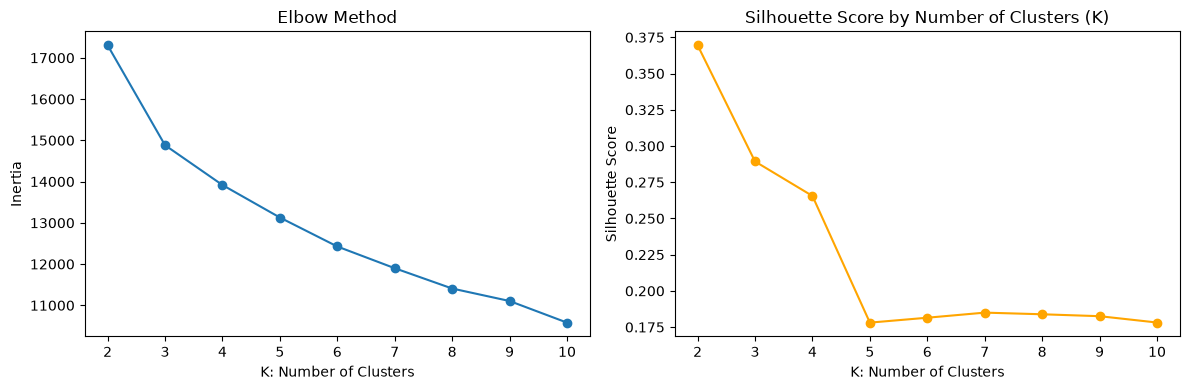

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(list(k_range), inertias, marker='o')
axes[0].set_xlabel('K: Number of Clusters')
axes[0].set_ylabel('Inertia')
axes[0].set_title('Elbow Method')

axes[1].plot(list(k_range), silhouettes, marker='o', color='orange')
axes[1].set_xlabel('K: Number of Clusters')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Silhouette Score by Number of Clusters (K)')

plt.tight_layout()
plt.show()

**Reading the charts — we choose K = 3.** The elbow drops steeply up to 3 and then flattens, so beyond 3 extra groups barely tighten things. Silhouette may peak at 2, but 2 groups is too coarse to act on, and the score is still strong at 3 before falling off at 5+. **K = 3 is the balance**: enough segments to be useful, few enough to stay meaningful.

# 4. Cluster with K-Means (main method)

**Fitting the final model with K = 3** and tagging every customer with their group (0, 1 or 2).

In [9]:
k_final = 3
kmeans = KMeans(n_clusters=k_final, random_state=42, n_init=10)
customers['cluster'] = kmeans.fit_predict(X_scaled)

customers['cluster'].value_counts().sort_index()

cluster
0     615
1    1024
2     577
Name: count, dtype: int64

**Profiling the groups — the heart of the business question.** We average every feature within each cluster to describe *who they are*. Read down each column to see which group is low / mid / high on income and spending.

In [10]:
profile = customers.groupby('cluster')[features].mean().round(2)
profile

,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,Recency,Income
cluster,,,,,,,,,,,,
0,468.83,19.34,134.78,27.18,19.85,59.22,3.67,6.27,3.03,7.58,47.68,58199.77
1,41.14,4.84,22.25,7.18,5.04,14.52,1.98,2.05,0.54,3.22,49.12,34972.51
2,599.01,72.02,458.22,102.84,73.71,79.97,1.49,5.36,6.07,8.48,50.24,76560.14


# 5. Confirm with a second method (Gaussian Mixture)

Relying on one algorithm is risky — maybe the groups are just an artifact of how K-Means works. So we re-run the segmentation with a different algorithm, **Gaussian Mixture (GMM)**, on the same data and same 3 groups. Where K-Means draws hard boundaries, GMM models the data as 3 overlapping "blobs" and gives each customer a *probability* of belonging to each. If both methods find the same groups, we can trust the segments are real.

In [11]:
gmm = GaussianMixture(n_components=3, covariance_type='full', random_state=42, n_init=10)
customers['gmm_cluster'] = gmm.fit_predict(X_scaled)

# Compare cluster quality on the same footing
kmeans_sil = silhouette_score(X_scaled, customers['cluster'])
gmm_sil    = silhouette_score(X_scaled, customers['gmm_cluster'])
print(f'K-Means silhouette: {kmeans_sil:.3f}')
print(f'GMM silhouette:     {gmm_sil:.3f}')

K-Means silhouette: 0.289
GMM silhouette:     0.164


**Do the two methods agree?** This cross-tab counts customers shared between each K-Means group and each GMM group. The group *numbers* are arbitrary, so don't expect a neat diagonal — instead look for **one big number in each row and column**, which means both methods basically found the same people together.

In [12]:
pd.crosstab(customers['cluster'], customers['gmm_cluster'],
            rownames=['K-Means'], colnames=['GMM'])

GMM,0,1,2
K-Means,,,
0,341,274,0
1,277,19,728
2,0,577,0


# 6. Visualize the groups

**Two summary numbers per customer.** To picture the business question on a flat chart, we build one number for each axis:

- **`spending_score`** — total of all six category spends (how *much* they spend).
- **`total_purchases`** — total of all four purchase channels: web + catalog + store + deals (how *often* / *how* they buy).

In [13]:
# Spending: how much they spend across all six categories
customers['spending_score'] = (
    customers['MntWines'] + customers['MntFruits'] + customers['MntMeatProducts'] +
    customers['MntFishProducts'] + customers['MntSweetProducts'] + customers['MntGoldProds']
)

# Purchasing behavior: how many purchases they make across all channels
customers['total_purchases'] = (
    customers['NumWebPurchases'] + customers['NumCatalogPurchases'] +
    customers['NumStorePurchases'] + customers['NumDealsPurchases']
)

**Spending vs purchasing behavior, coloured by K-Means group.** This is the chart that matches the business question directly: the x-axis is *how often* customers buy (total purchases) and the y-axis is *how much* they spend. If the groups separate here, they differ in real buying behavior — not just in income.

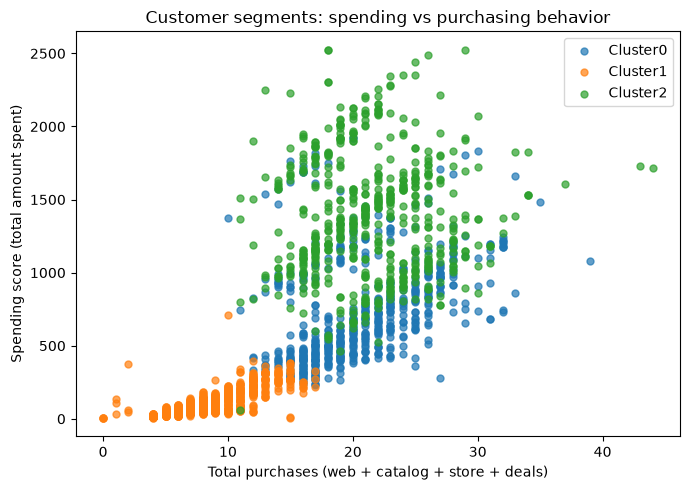

In [14]:
x, y = 'total_purchases', 'spending_score'
fig, ax = plt.subplots(figsize=(7, 5))
cmap = plt.get_cmap('tab10')

for c in range(k_final):
    mask = customers['cluster'] == c
    ax.scatter(customers.loc[mask, x], customers.loc[mask, y],
               s=25, alpha=0.7, color=cmap(c), label=f'Cluster{c}')

ax.set_xlabel('Total purchases (web + catalog + store + deals)')
ax.set_ylabel('Spending score (total amount spent)')
ax.set_title('Customer segments: spending vs purchasing behavior')
ax.legend()
plt.tight_layout()
plt.show()

**Seeing all 12 features at once with PCA.** We can't plot 12 dimensions, so PCA squeezes them into 2 combined axes that keep as much of the variation as possible. First, how much information the top components hold:

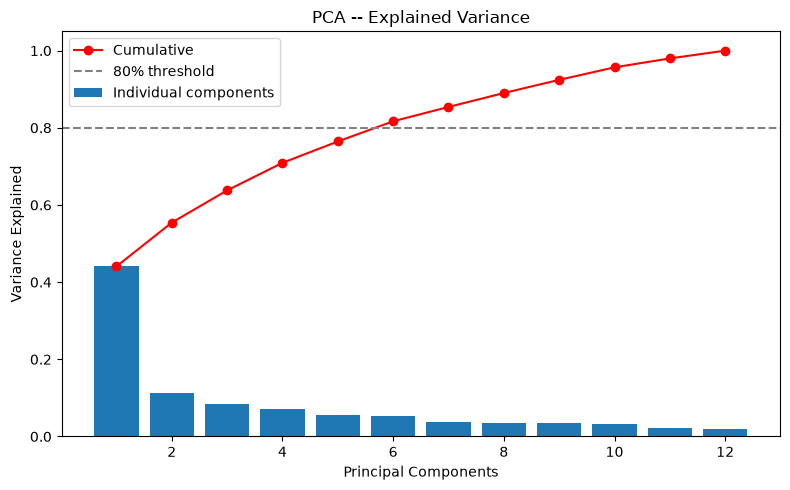

In [15]:
pca = PCA()
pca.fit(X_scaled)

plt.figure(figsize=(8, 5))
plt.bar(range(1, len(features) + 1), pca.explained_variance_ratio_, label='Individual components')
plt.plot(range(1, len(features) + 1), np.cumsum(pca.explained_variance_ratio_),
         marker='o', color='red', label='Cumulative')
plt.axhline(0.80, color='gray', linestyle='--', label='80% threshold')
plt.xlabel('Principal Components')
plt.ylabel('Variance Explained')
plt.title('PCA -- Explained Variance')
plt.legend()
plt.tight_layout()
plt.show()

**The 2D map of customers, coloured by group, with the K-Means centers marked.** This is the whole customer base flattened to two PCA axes so we can eyeball how well-separated the segments are.

These 2 components capture 55.4% of the total variation


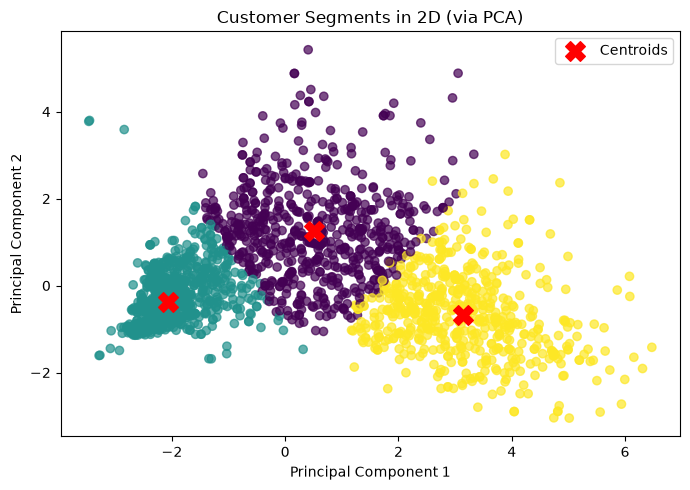

In [16]:
pca_2d = PCA(n_components=2)
X_2d = pca_2d.fit_transform(X_scaled)
print(f'These 2 components capture {pca_2d.explained_variance_ratio_.sum():.1%} of the total variation')

plt.figure(figsize=(7, 5))
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=customers['cluster'], cmap='viridis', alpha=0.7)

# project the K-Means centers into the same 2D space
centers_2d = pca_2d.transform(kmeans.cluster_centers_)
plt.scatter(centers_2d[:, 0], centers_2d[:, 1], c='red', marker='X', s=200, label='Centroids')

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('Customer Segments in 2D (via PCA)')
plt.legend()
plt.tight_layout()
plt.show()

# 7. Answer: what customer groups did we find?

Using the profile table in Section 4, give each cluster a plain-English name and a recommended action. **Match the cluster numbers to your actual output** — the row with the highest income/spending is your premium group, the lowest is budget, the rest is the middle. A typical result for this dataset looks like:

| Segment | Who they are | What the business should do |
|---|---|---|
| **Premium** (high income, high spend) | Best customers, buy across categories | Protect them — loyalty perks, VIP tiers, early access |
| **Standard** (mid income, mid spend) | The "movable middle" with headroom | Grow them — bundles, cross-sell, spend-more-get-more offers |
| **Budget** (low spend) | Low spenders; watch for high-income low-spenders | Activate the high-income ones; use value offers for the rest |

**So, answering the business question:** the customer base splits into roughly **three behavior-based groups — Budget, Standard and Premium** — and both K-Means and GMM agree on them, so the segmentation is stable enough to act on.

**Honest caveat (for the write-up):** these groups describe *who* customers are, not *why* they spend. They are a starting point for targeting, best confirmed with a small A/B test before rolling out any campaign. Fill the summary below with your real numbers once you run the notebook.

In [17]:
# Quick reference: size, income and spending of each group to fill in the names above
summary = customers.groupby('cluster').agg(
    n_customers=('cluster', 'size'),
    avg_income=('Income', 'mean'),
    avg_spending=('spending_score', 'mean')
).round(0).sort_values('avg_spending')
summary

,n_customers,avg_income,avg_spending
cluster,,,
1,1024,34973.0,95.0
0,615,58200.0,729.0
2,577,76560.0,1386.0
